# 12. 알려진 불량 메커니즘 검증 (physics check)

**방식**: 가설·지표·예상 방향을 `physics_check.py`의 `HYP`에 **결과 보기 전에 고정** → 단측 검정 + Run별 방향 일치 → 판정
- 판정: **지지** (예상 방향 δ ≥ 0.33, p < 0.05) / **약한 지지** (≥ 0.147) / **근거 없음** / **반대** (예상 반대로 ≥ 0.147)
- 비교: Run 안 표준화(라벨 미사용) 후 같은 Run 정상 전체 / 불량 앞뒤 ±10샷 정상

| 메커니즘 | 지표 | 예상 |
|---|---|---|
| 미성형① 재료부족 | 재료부족(충전↓·속도↑·압력↓), 계량지연, 쿠션부족 | + |
| 미성형② 압력한계 | 압력한계, 점도잔차 | + |
| 미성형③ 조기고화 | 금형냉각 | + |
| 가스① 디젤효과 | 사출속도 | + |
| 가스② 열분해 | 체류시간(사이클), 배럴최고온도, 점도잔차 | +, +, − |
| 탐색 | 호퍼온도 | ? |

In [1]:
%load_ext autoreload
%autoreload 2
import os
import pandas as pd
from run_compare import load_product
from physics_check import (physics_consistency, build_indices, standardize_indices, test_hypotheses,
                           plot_consistency, plot_verdict, plot_index_strips, HYP)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
OUT = './outputs/physics'
os.makedirs(OUT, exist_ok=True)
PRODUCTS = ['cn7', 'rg3']
D = {p: load_product(p)[0] for p in PRODUCTS}

[cn7] 샷 1974, 불량 15
[rg3] 샷 627, 불량 32


## 0. 물리 일관성 — 온도↑ → 흐름저항(점도)↓ 인가
Run 안 편차끼리 회귀(라벨 미사용). 배럴·금형 계수가 **음수**면 흐름저항을 점도 대리 지표로 쓸 근거가 됨.
반대거나 0이면 → 이 데이터의 온도 변동이 너무 작거나(기록 단위 수준), 흐름저항이 점도 말고 다른 것(설정·측정)에 좌우된다는 뜻 → 점도 관련 판정은 약하게 해석

[cn7] within R² = 0.048


,변수,계수(%/℃),SE,t,예상 부호,일치
0,Barrel_Temperature_1_raw,0.044,0.033,1.326,-1,반대(약함)
1,Barrel_Temperature_2_raw,0.035,0.038,0.915,-1,반대(약함)
2,Barrel_Temperature_3_raw,-0.107,0.045,-2.357,-1,일치(유의)
3,Barrel_Temperature_4_raw,0.015,0.017,0.851,-1,반대(약함)
4,Barrel_Temperature_5_raw,0.005,0.043,0.117,-1,반대(약함)
5,Barrel_Temperature_6_raw,-0.181,0.063,-2.879,-1,일치(유의)
6,Mold_Temperature_3_raw,-0.138,0.022,-6.270,-1,일치(유의)
7,Hopper_Temperature_raw,-0.037,0.023,-1.606,0,탐색


[rg3] within R² = 0.118


,변수,계수(%/℃),SE,t,예상 부호,일치
0,Barrel_Temperature_1_raw,0.042,0.015,2.812,-1,반대(유의)
1,Barrel_Temperature_2_raw,0.006,0.014,0.440,-1,반대(약함)
2,Barrel_Temperature_3_raw,-0.016,0.019,-0.842,-1,일치(약함)
3,Barrel_Temperature_4_raw,0.043,0.009,4.931,-1,반대(유의)
4,Barrel_Temperature_5_raw,-0.054,0.018,-2.925,-1,일치(유의)
5,Barrel_Temperature_6_raw,-0.180,0.029,-6.231,-1,일치(유의)
6,Mold_Temperature_3_raw,0.061,0.034,1.785,-1,반대(약함)
7,Hopper_Temperature_raw,-0.014,0.011,-1.237,0,탐색


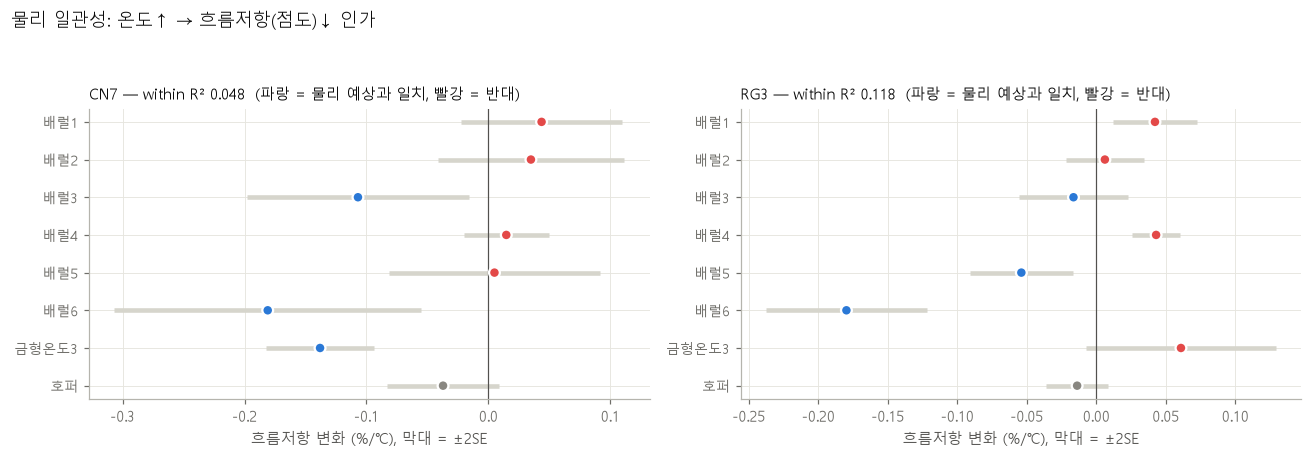

In [2]:
CONS, RESID = {}, {}
for p in PRODUCTS:
    t, RESID[p], r2 = physics_consistency(D[p])
    CONS[p] = (t, r2)
    t.to_csv(f'{OUT}/consistency_{p}.csv', index=False, encoding='utf-8-sig')
    print(f'[{p}] within R² = {r2:.3f}'); display(t.round(3))
plot_consistency(CONS, save=f'{OUT}/consistency.png')

## 1. 메커니즘 지표 계산 (라벨 미사용) → Run 안 표준화

In [3]:
IZ = {}
for p in PRODUCTS:
    IZ[p] = standardize_indices(D[p], build_indices(D[p], RESID[p]))
# 두 제품 합친 버전 (Run 안 표준화라 합쳐도 됨)
D['both'] = pd.concat([D['cn7'], D['rg3']], ignore_index=True)
IZ['both'] = pd.concat([IZ['cn7'], IZ['rg3']], ignore_index=True)
display(IZ['rg3'].describe().round(2))

,재료부족,계량지연,쿠션부족,압력한계,점도잔차,금형냉각,디젤(속도),체류시간,배럴최고온도,호퍼(탐색)
count,627.00,627.00,627.00,627.00,627.00,627.00,627.00,627.00,627.00,627.00
mean,0.00,0.01,-0.17,-0.06,-0.03,0.17,-0.01,-0.33,-0.02,-0.11
std,0.82,0.86,0.83,0.70,0.74,0.85,0.73,1.59,0.70,1.19
min,-2.33,-2.75,-4.00,-3.00,-2.39,-2.00,-2.00,-4.56,-2.20,-4.00
25%,-0.57,-0.50,-0.50,-0.50,-0.52,-0.50,-0.50,-1.00,-0.50,-0.58
50%,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,0.50,0.50,0.00,0.50,0.49,0.67,0.50,0.00,0.44,0.33
max,3.00,2.67,2.00,2.00,2.14,3.00,2.00,21.00,1.67,7.00


## 2. 가설 검정

,제품,메커니즘,지표,불량군,예상,n불량,δ_전체,p_전체,판정_전체,δ_±10샷,p_±10샷,판정_±10샷,예상방향_Run
0,cn7,미성형① 재료부족,재료부족,미성형계열,+,4,0.746,0.005,지지,0.734,0.010,지지,1/2
1,cn7,미성형① 재료부족,계량지연,미성형계열,+,4,0.240,0.203,약한 지지,0.032,0.469,근거 없음,1/2
2,cn7,미성형① 재료부족,쿠션부족,미성형계열,+,4,0.711,0.002,지지,0.742,0.000,지지,2/2
3,cn7,미성형② 압력한계,압력한계,미성형계열,+,4,-0.741,0.997,반대,-0.790,0.997,반대,0/2
4,cn7,미성형② 압력한계,점도잔차,미성형계열,+,4,-0.712,0.993,반대,-0.694,0.990,반대,1/2
5,cn7,미성형③ 조기고화,금형냉각,미성형계열,+,4,-0.677,0.990,반대,-0.089,0.625,근거 없음,0/2
6,cn7,가스① 디젤효과,디젤(속도),가스,+,11,-0.003,0.507,근거 없음,-0.145,0.775,근거 없음,0/1
7,cn7,가스② 열분해,체류시간,가스,+,11,0.005,0.488,근거 없음,-0.130,0.796,근거 없음,0/1
8,cn7,가스② 열분해,배럴최고온도,가스,+,11,-0.066,0.648,근거 없음,-0.107,0.710,근거 없음,0/1
9,cn7,가스② 열분해,점도잔차,가스,−,11,0.088,0.692,근거 없음,0.236,0.885,반대,0/1


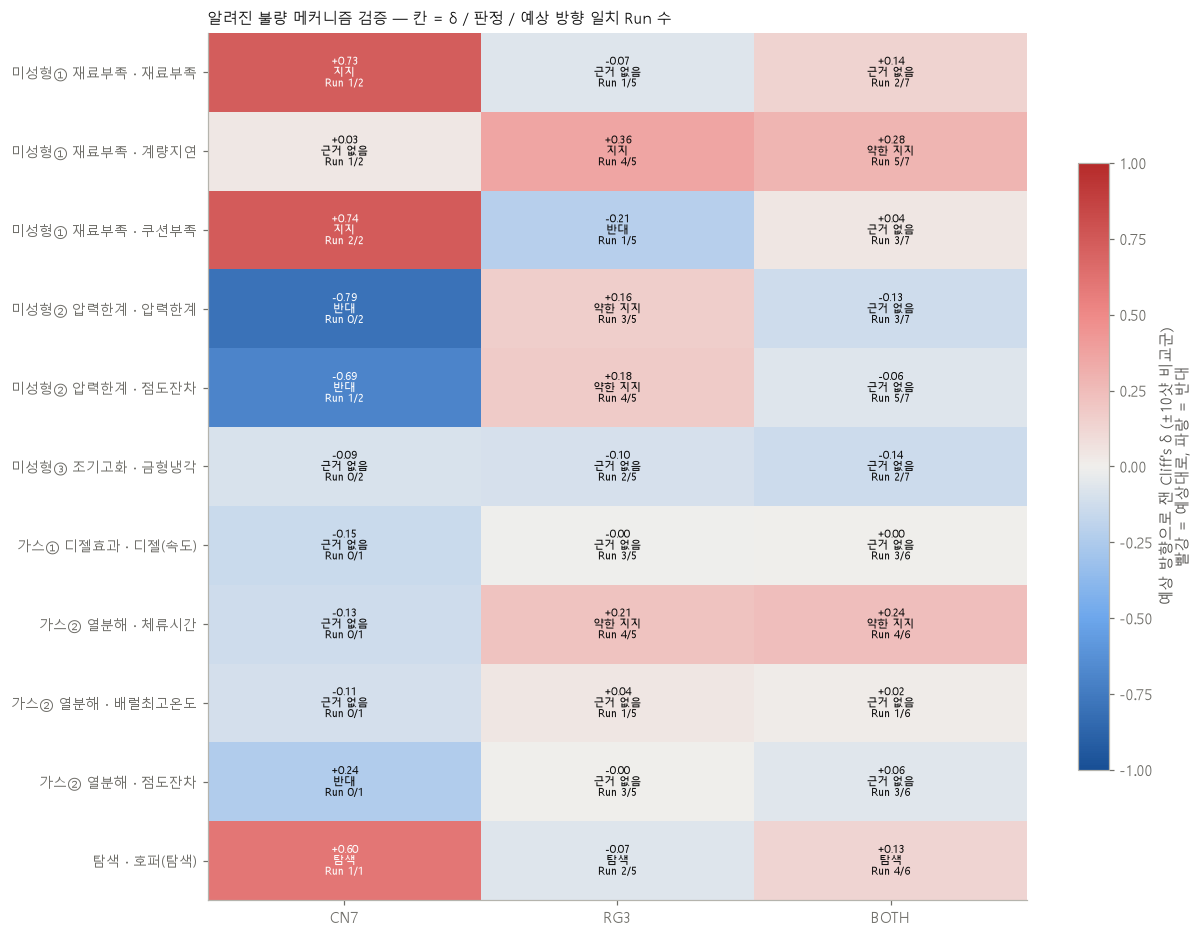

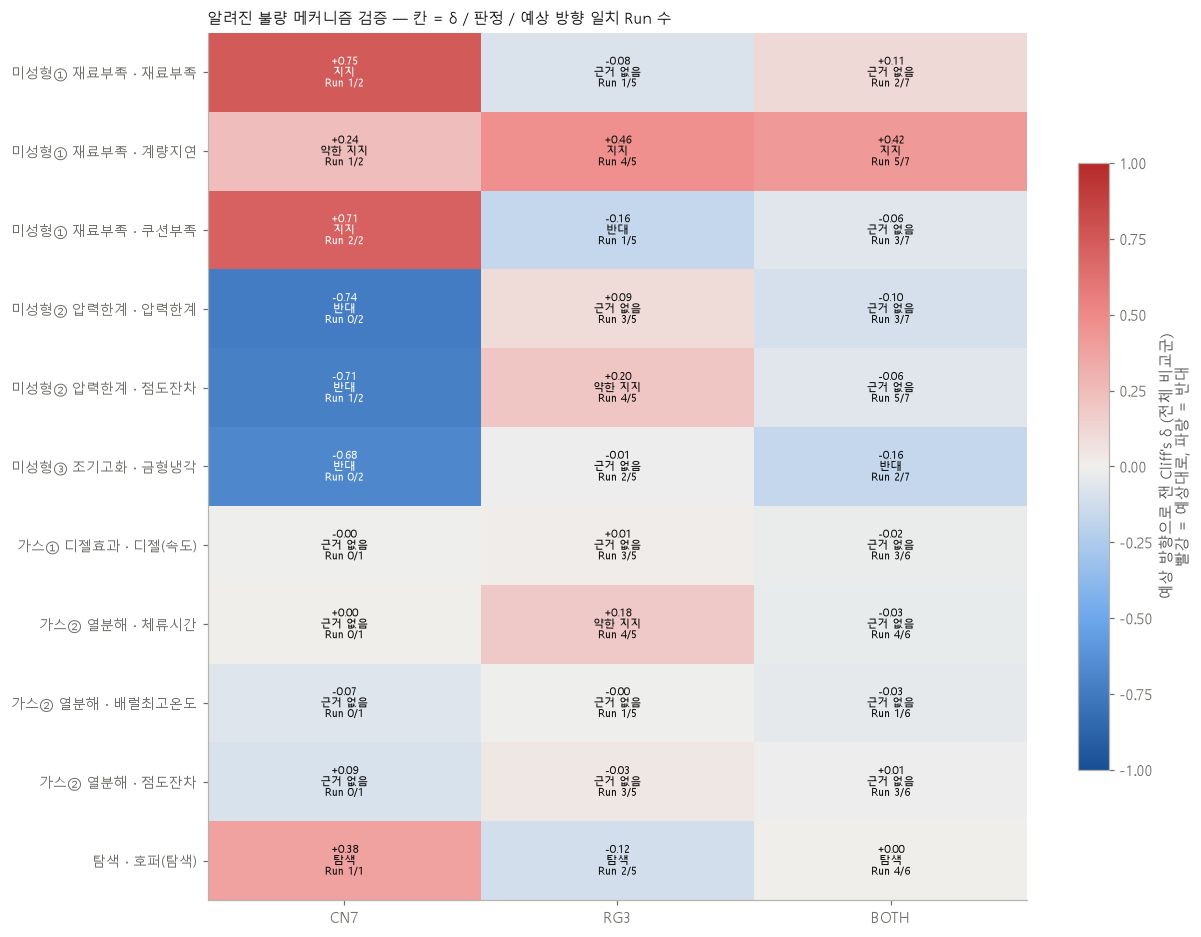

In [4]:
RES = pd.concat([test_hypotheses(D[p], IZ[p], p) for p in ['cn7', 'rg3', 'both']], ignore_index=True)
RES.to_csv(f'{OUT}/verdict.csv', index=False, encoding='utf-8-sig')
show = ['제품', '메커니즘', '지표', '불량군', '예상', 'n불량', 'δ_전체', 'p_전체', '판정_전체',
        'δ_±10샷', 'p_±10샷', '판정_±10샷', '예상방향_Run']
display(RES[show].round(3))
plot_verdict(RES, '±10샷', save=f'{OUT}/verdict_matched.png')
plot_verdict(RES, '전체', save=f'{OUT}/verdict_all.png')

## 3. 지표 분포

c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\physics_check.py:253: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.tight_layout(rect=(0, 0, 1, 0.95))
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\physics_check.py:255: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.savefig(save)
c:\anaconda\envs\kamp\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


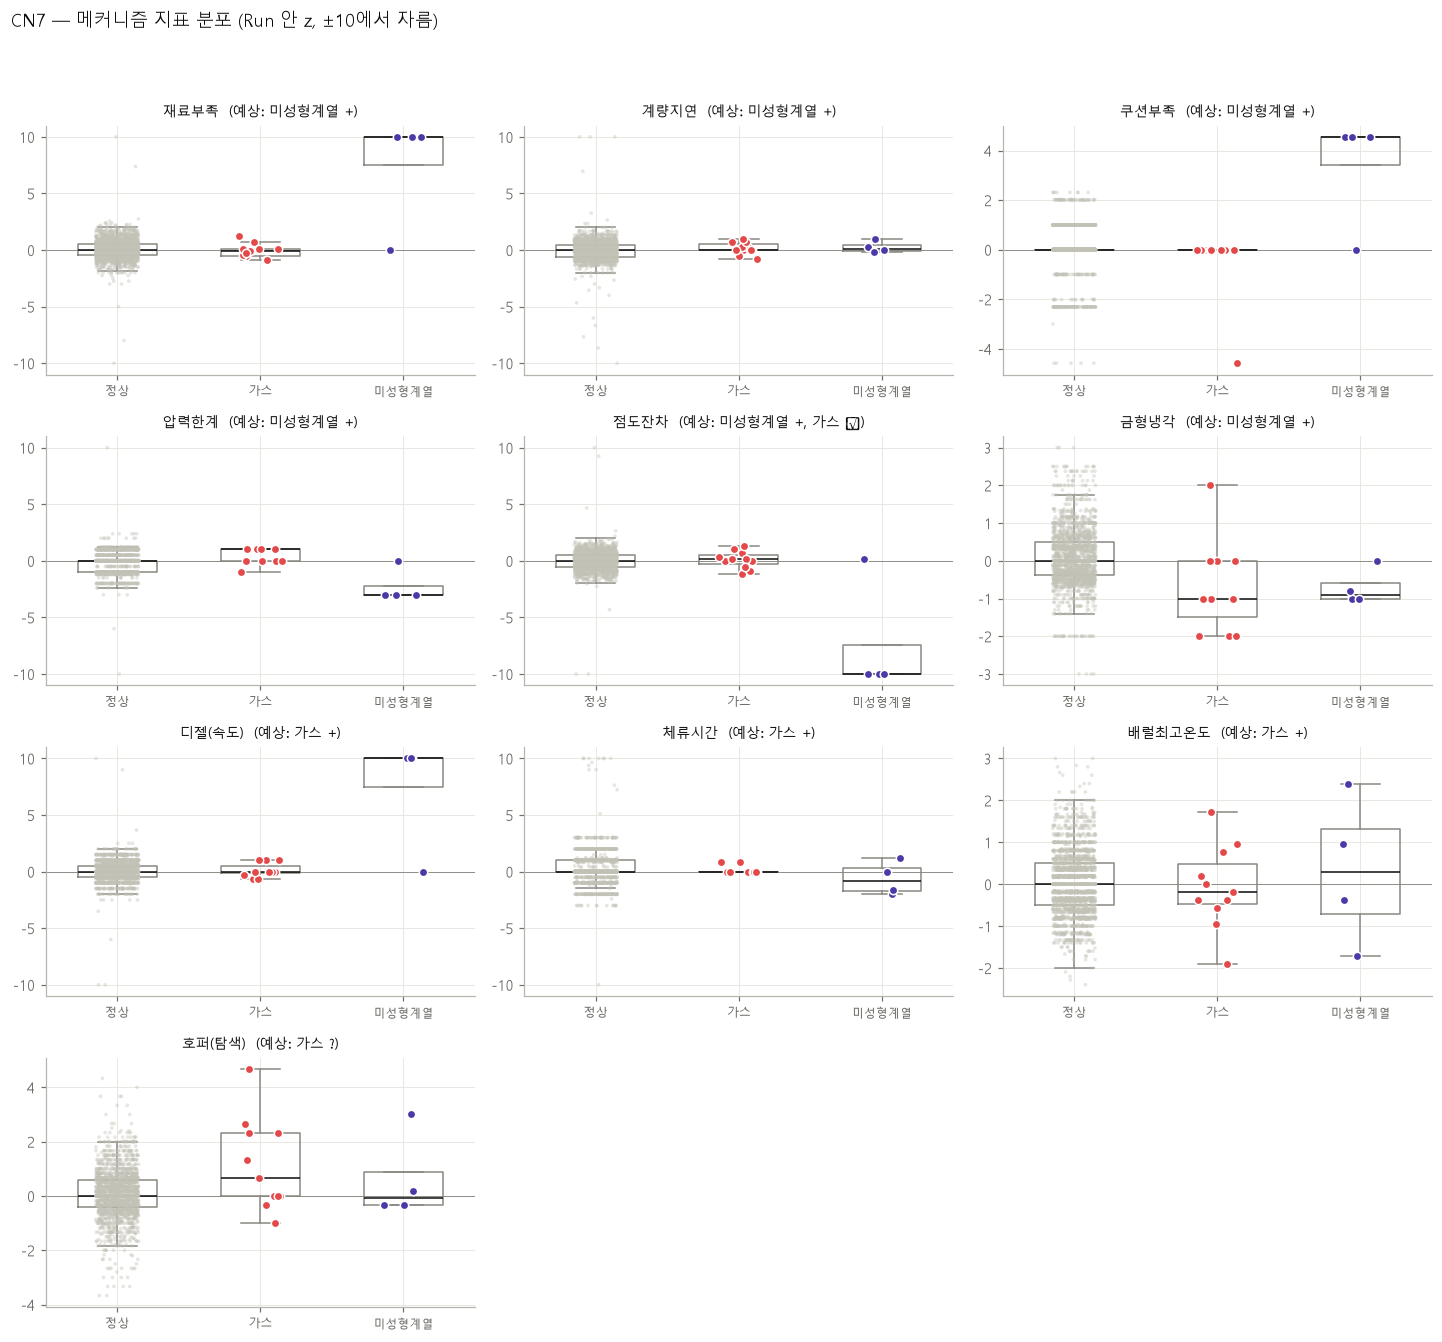

c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\physics_check.py:253: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.tight_layout(rect=(0, 0, 1, 0.95))
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\physics_check.py:255: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.savefig(save)
c:\anaconda\envs\kamp\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


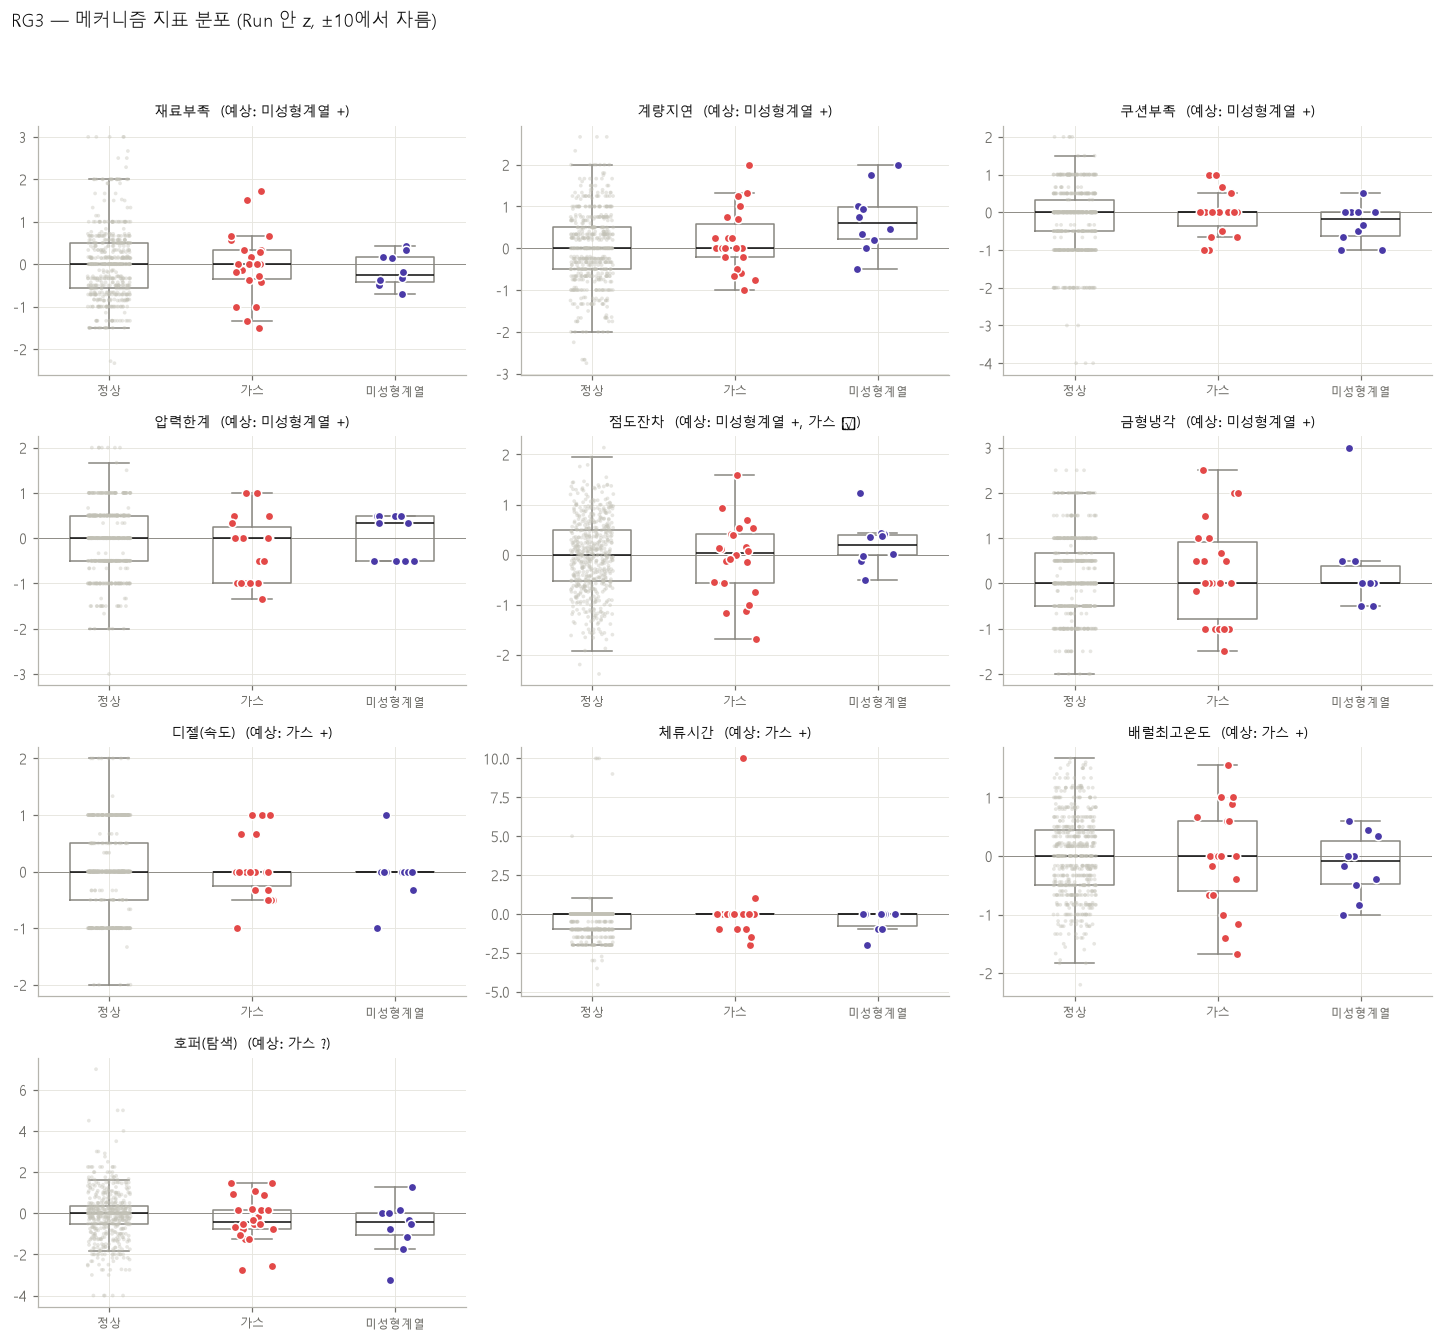

In [5]:
for p in PRODUCTS:
    plot_index_strips(D[p], IZ[p], p, save=f'{OUT}/strips_{p}.png')

## 4. 가스② 열분해 — 체류시간 vs 배럴온도 따로 보기
예전에는 `ln(사이클) − Ea/RT` 하나로 합쳤는데, Run 안 변동에서는 온도 항이 수십 배 커서 Ea를 얼마로 두든 사실상 배럴온도만 보게 됨 → 두 지표로 분리.
둘 다 '지지'면 체류×온도 모두, 한쪽만이면 그쪽 경로만 근거가 있음

In [6]:
g2 = RES[RES['메커니즘'] == '가스② 열분해']
display(g2[['제품', '지표', '예상', 'n불량', 'δ_전체', '판정_전체', 'δ_±10샷', '판정_±10샷', '예상방향_Run']].round(3))

,제품,지표,예상,n불량,δ_전체,판정_전체,δ_±10샷,판정_±10샷,예상방향_Run
7,cn7,체류시간,+,11,0.005,근거 없음,-0.130,근거 없음,0/1
8,cn7,배럴최고온도,+,11,-0.066,근거 없음,-0.107,근거 없음,0/1
9,cn7,점도잔차,−,11,0.088,근거 없음,0.236,반대,0/1
18,rg3,체류시간,+,22,0.181,약한 지지,0.214,약한 지지,4/5
19,rg3,배럴최고온도,+,22,-0.001,근거 없음,0.041,근거 없음,1/5
20,rg3,점도잔차,−,22,-0.033,근거 없음,-0.000,근거 없음,3/5
29,both,체류시간,+,33,-0.030,근거 없음,0.237,약한 지지,4/6
30,both,배럴최고온도,+,33,-0.032,근거 없음,0.018,근거 없음,1/6
31,both,점도잔차,−,33,0.008,근거 없음,0.057,근거 없음,3/6


## 해석 가이드
- **0번이 먼저**: 배럴·금형 계수가 음수(일치)가 아니면 '점도잔차' 관련 판정은 근거가 약함
- **판정은 ±10샷 비교군 기준**, 전체 비교군과 방향이 다르면 시간 추세 영향 → 보류
- **예상방향_Run**: 여러 Run에서 같은 방향이어야 일반적인 메커니즘. CN7은 미성형이 R1·R6, 가스는 R1뿐 → CN7 판정은 사실상 Run 1개 기준
- 다중 검정: 가설 10개 × 3 → p는 참고, **방향 + 효과크기 + Run 일치**로 판단
- 보고서 문장 형태: "알려진 메커니즘 A는 (지지/반대), B는 데이터로 확인 불가(측정 변수 없음)"
- 측정 안 되는 메커니즘(벤트 막힘, 수분, 금형 내 압력)은 '검증 불가'로 따로 명시